# Crohn's extraction pipeline · v2 (docs-aligned)

Same pipeline as `pipeline.ipynb`, with one addition from the official litellm Anthropic docs: a **smoke-test cell** that makes a single `completion()` call so you get an immediate yes/no on key + model + connectivity *before* extracting 50 transcripts.

Per the docs: model is `provider/model` (e.g. `anthropic/claude-sonnet-4-6`); Anthropic requires `max_tokens` (litellm defaults to 4096 if omitted); the key is read from the `ANTHROPIC_API_KEY` environment variable. Cache-first otherwise — runs end to end with no key.

## 1 · Imports

In [1]:
import os
# This notebook lives in notebooks/ but all paths (data/, src/) are repo-root-
# relative -- hop up one level if launched from inside notebooks/, no-op otherwise.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import os, json, sys
from pathlib import Path
from collections import Counter
import pandas as pd
sys.path.insert(0, 'src')
from schema import PatientRecord
import derive, queries
print('imports ok · pandas', pd.__version__)

imports ok · pandas 2.2.3


## 2 · Environment & API key

In [2]:
ENV_PATH = Path('.env').resolve()
loaded = False
try:
    from dotenv import load_dotenv
    loaded = load_dotenv(ENV_PATH)
except ImportError:
    print('!! python-dotenv not installed -> run:  pip install -r requirements.txt')
# Only ANTHROPIC_API_KEY matters here -- this notebook's extraction always runs
# through extract.py's default model (Claude Sonnet). Gemini is a separate,
# opt-in comparison in notebooks/evaluation.ipynb, not an alternate path here.
HAS_KEY = bool(os.getenv('ANTHROPIC_API_KEY'))
print(f'.env at {ENV_PATH}: {"found" if ENV_PATH.exists() else "MISSING"}  (loaded={loaded})')
print('ANTHROPIC_API_KEY detected:', HAS_KEY)
if not HAS_KEY:
    print('\nNo key found. Put  ANTHROPIC_API_KEY=sk-ant-...  in a .env file in this folder.')
print('\nLive extraction enabled:', HAS_KEY, '' if HAS_KEY else '(cache-first demo)')


.env at /Users/hussami/Downloads/Data-Science-Challenge-main/.env: found  (loaded=True)
API keys detected: {'anthropic': True, 'gemini': False, 'google': False}

Live extraction enabled: True 


## 3 · Model parameters

`provider/model` form (docs). A bare `claude-...` id is auto-prefixed with `anthropic/` by `extract.py`, but keeping the prefix here is the documented way.

In [3]:
MODEL = 'anthropic/claude-sonnet-4-6'   # docs use dated ids too, e.g. 'anthropic/claude-3-5-sonnet-latest'
TEMPERATURE = 0
MAX_TOKENS = 4000
CACHE_DIR = Path('data/cache'); CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(dict(model=MODEL, temperature=TEMPERATURE, max_tokens=MAX_TOKENS, cache=str(CACHE_DIR)))

{'model': 'anthropic/claude-sonnet-4-6', 'temperature': 0, 'max_tokens': 4000, 'cache': 'data/cache'}


## 3b · litellm smoke test (from the official docs)

A single `completion()` call, exactly the docs' first example. If your key + model work, you see a reply here; if not, you get the precise error now — not 50 errors later. Skips cleanly with no key.

In [4]:
if HAS_KEY:
    from litellm import completion
    try:
        resp = completion(model=MODEL,
                          messages=[{'role': 'user', 'content': 'Reply with exactly: OK'}],
                          max_tokens=10, temperature=0)
        print('live call OK ->', resp.choices[0].message.content)
    except Exception as e:
        print('live call FAILED ->', type(e).__name__, str(e)[:200])
else:
    print('no key -> skipping smoke test (cache-first demo)')

live call OK -> OK


## 4 · Load transcripts

In [5]:
interviews = json.loads(Path('data/interviews.json').read_text())
print(len(interviews), 'transcripts')
ex = interviews[0]
print(ex['patient_id'], '—', ex['interview_transcript'][:160], '...')

50 transcripts
P001 — I'm Sarah, 34 years old, and I've been dealing with Crohn's for about eight years now. It all started when I was 26, working as a marketing manager in Chicago.  ...


## 5 · The extraction prompt (uncertainty instructions)

Imported from `src/extract.py` — single source of truth, same prompt `extract_one` uses.

In [6]:
from extract import SYSTEM_PROMPT
print(SYSTEM_PROMPT[:600], '...')

You extract structured data from a single Crohn's disease patient interview into the PatientRecord JSON schema. Honesty about uncertainty matters more than completeness.

For EVERY field, set `status` to the epistemic basis:
  - stated: the value is given verbatim. Put the quote in `evidence`.
  - inferred: you reasoned it (not quoted). Put the reasoning basis in `evidence` and a confidence < 1. Example: patient lists current meds in present tense with no biologic among them -> biologic.status value 'not_on', status 'inferred'.
  - denied: explicitly ruled out ('never tried X', 'no other condi ...


## 6 · The extraction function

`extract_one` (in `src/extract.py`) is prompt-based JSON: schema in the prompt, validate against `PatientRecord`, self-correct once. No provider `response_format` (it choked on our generic `Signal[T]`). Follows the docs: `completion()` with `max_tokens`, `anthropic/` routing.

In [7]:
from extract import extract_one
print('extract_one imported from src/extract.py (prompt-based JSON + 1 retry)')

extract_one imported from src/extract.py (prompt-based JSON + 1 retry)


## 7 · Run the pipeline (resumable, force-refresh)

Shares its loop with `src/run_extraction.py` (`run_extraction.run(...)`), so the notebook and the terminal script can't drift apart. This is a **force-refresh**, not the plain cache-first check you'd expect — a prompt change makes old cache files stale, and "the file exists" can't tell stale-old apart from already-redone-this-pass. Instead it keeps its own resume manifest (`data/cache/_reextraction_manifest.json`): a patient already in the manifest is skipped, so re-running this cell after a rate-limit interruption only retries what didn't finish — it never re-spends quota on patients that already succeeded. On a failure that looks like a rate limit, it cools down before the next attempt instead of hammering the API again immediately, and it stops itself after 3 failures in a row rather than grinding through the rest on a sustained limit. Safe to interrupt (Kernel -> Interrupt) at any point — each success is written to disk immediately, nothing already done is ever lost.

In [8]:
from run_extraction import run as run_extraction_pass

result = run_extraction_pass(interviews)
if result["failed"] or result["stopped_early"]:
    print(f"\n{len(result['failed'])} patient(s) still failing this pass "
          f"(stopped_early={result['stopped_early']}): {result['failed']}")
    print("Re-run this cell to retry just those -- everything else is skipped via the manifest.")
else:
    print("\nAll 50 patients extracted successfully.")


model=anthropic/claude-sonnet-4-6  n=50  throttle=5.0s  already re-extracted this pass=30
[1/50] P001 SKIP (already re-extracted this pass)
[2/50] P002 SKIP (already re-extracted this pass)
[3/50] P003 SKIP (already re-extracted this pass)
[4/50] P004 SKIP (already re-extracted this pass)
[5/50] P005 SKIP (already re-extracted this pass)
[6/50] P006 SKIP (already re-extracted this pass)
[7/50] P007 SKIP (already re-extracted this pass)
[8/50] P008 SKIP (already re-extracted this pass)
[9/50] P009 SKIP (already re-extracted this pass)
[10/50] P010 SKIP (already re-extracted this pass)
[11/50] P011 SKIP (already re-extracted this pass)
[12/50] P012 SKIP (already re-extracted this pass)
[13/50] P013 SKIP (already re-extracted this pass)
[14/50] P014 SKIP (already re-extracted this pass)
[15/50] P015 SKIP (already re-extracted this pass)
[16/50] P016 SKIP (already re-extracted this pass)
[17/50] P017 SKIP (already re-extracted this pass)
[18/50] P018 SKIP (already re-extracted this pass)
[

In [9]:
# Load whatever is in the cache right now — works even if the run above is partial
# (some patients still pending a retry), so the rest of the notebook always has
# something to show rather than failing outright.
records = [PatientRecord.model_validate_json(f.read_text())
           for f in sorted(Path('data/cache').glob('P*.json'))]
print(f'loaded {len(records)}/{len(interviews)} records from cache')


loaded 50/50 records from cache


## 8 · Save state — typed records + flat CSV frames

In [10]:
OUT = Path('data/outputs'); OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'records.json').write_text(json.dumps([json.loads(r.model_dump_json()) for r in records], indent=1))
patients, treatments, encounters = queries.to_frames(records)
patients.to_csv(OUT / 'patients.csv', index=False)
treatments.to_csv(OUT / 'treatments.csv', index=False)
encounters.to_csv(OUT / 'encounters.csv', index=False)
print('wrote:', sorted(p.name for p in OUT.glob('*')))
patients

wrote: ['analysis_summary.json', 'charts', 'encounters.csv', 'patients.csv', 'records.json', 'treatments.csv']


,patient_id,age,years_since_dx,occupation,comorbidities,location,severity,severity_basis,symptoms,disease_control,disease_control_basis,on_biologic,biologic_status,biologic_basis,completeness,churn,referral_steps
0,P001,34,8.00,marketing manager,[psoriasis],ileocolonic,moderate_to_severe,stated,"[abdominal_pain, diarrhea, weight_loss]",remission,stated,True,on,stated,complete,False,2.0
1,P002,42,3.00,high school teacher,"[type 2 diabetes, anemia, stroke (minor, 2 yea...",ileocolonic,moderate_to_severe,inferred,"[abdominal_pain, bloody_diarrhea, nausea_vomit...",partial,inferred,False,planned,stated,complete,False,2.0
2,P003,28,12.00,remote work,"[anxiety disorder, PCOS, osteopenia]",None,moderate_to_severe,inferred,"[fatigue, joint, skin, fistula, abdominal_pain...",partial,inferred,True,on,stated,complete,False,3.0
3,P004,55,0.50,construction business owner,"[hypertension, high cholesterol, depression]",colonic,moderate_to_severe,inferred,"[abdominal_pain, fatigue, joint, bowel_obstruc...",poor,inferred,False,discussed_rejected,stated,complete,False,2.0
4,P005,31,5.00,None,"[endometriosis, migraines, Humira-induced psor...",ileocolonic,moderate,inferred,"[abdominal_pain, fatigue, skin]",partial,inferred,True,on,stated,complete,False,3.0
5,P006,38,10.00,IT worker,"[depression, sleep apnea, short bowel syndrome...",ileocolonic,moderate_to_severe,inferred,"[fatigue, bowel_obstruction, malnutrition]",partial,inferred,True,on,stated,complete,False,3.0
6,P007,45,3.00,teacher,"[hypothyroidism, fibromyalgia, osteoporosis, v...",small_intestine_other,moderate_to_severe,inferred,"[diarrhea, weight_loss, fatigue]",partial,stated,True,on,stated,complete,False,2.0
7,P008,29,8.00,remote tech worker,"[ADHD, generalized anxiety, kidney stones]",ileocolonic,moderate_to_severe,inferred,"[fatigue, abdominal_pain, bloody_diarrhea, bow...",partial,inferred,True,on,stated,complete,False,4.0
8,P009,36,3.00,finance,"[asthma, rheumatoid arthritis]",colonic,moderate_to_severe,inferred,"[weight_loss, fatigue, nausea_vomiting, joint,...",partial,inferred,True,on,stated,complete,False,3.0
9,P010,48,5.00,middle management,"[type 2 diabetes, enteropathic arthritis (Croh...",ileocolonic,severe,stated,"[diarrhea, weight_loss, joint, fatigue, abdomi...",partial,inferred,True,on,stated,complete,False,3.0


## 9 · Query — PharmaCorp's four questions

In [11]:
lo, hi, brk = derive.q1_range(records)
print(f'Q1  % on biologic (band): {lo:.0%}-{hi:.0%}   {brk}')
bar = Counter(b.type.value for r in records for b in r.biologic.barriers)
print('Q2  barriers (not-on):', dict(bar))
for r in records:
    print('Q3 ', r.patient_id, '->', ' -> '.join(derive.treatment_sequence(r)) or '(none)')
print('Q4  referral steps:', {r.patient_id: derive.referral_steps(r).value for r in records})

Q1  % on biologic (band): 72%-72%   {'stated_on': 36, 'inferred_on': 0, 'unknown': 0, 'off': 14, 'n': 50}
Q2  barriers (not-on): {'patient_fear': 13, 'cost_insurance': 25, 'step_therapy': 21, 'access': 1, 'comorbidity_risk': 11, 'surgery_first': 1}
Q3  P001 -> aminosalicylate -> immunomodulator
Q3  P002 -> corticosteroid -> aminosalicylate -> immunomodulator -> corticosteroid
Q3  P003 -> aminosalicylate -> aminosalicylate -> immunomodulator -> immunomodulator
Q3  P004 -> corticosteroid -> aminosalicylate -> aminosalicylate -> corticosteroid
Q3  P005 -> aminosalicylate -> corticosteroid -> immunomodulator
Q3  P006 -> immunomodulator
Q3  P007 -> corticosteroid -> immunomodulator
Q3  P008 -> corticosteroid -> aminosalicylate -> immunomodulator -> immunomodulator
Q3  P009 -> aminosalicylate -> corticosteroid -> immunomodulator
Q3  P010 -> corticosteroid -> immunomodulator -> aminosalicylate -> immunomodulator
Q3  P011 -> corticosteroid -> aminosalicylate -> immunomodulator
Q3  P012 -> amin

## 10 · Query — ad-hoc questions beyond the four

In [12]:
queries.q_drug_usefulness(treatments, 'mesalamine')
queries.q_best_treatment_for_symptom(patients, treatments, 'diarrhea')
queries.q_remission_by_tenure(patients, 5)


Q) Of people who tried "mesalamine", how many found it useful?
   tried: 40  |  outcome known: 40  |  useful (effective/partial): 11
patient_id                          name_raw          outcome
      P001                        mesalamine      ineffective
      P002                        mesalamine      ineffective
      P003                        mesalamine      ineffective
      P004                        mesalamine      ineffective
      P005                        mesalamine          partial
      P008                        mesalamine          partial
      P009                        mesalamine      ineffective
      P010                        mesalamine          partial
      P011                        mesalamine      ineffective
      P012                        mesalamine      ineffective
      P013                        Mesalamine          partial
      P015                        mesalamine      ineffective
      P016                        mesalamine      ineffectiv

## 11 · Evaluation — per-question accuracy

Golden-set agreement scored the way each PharmaCorp question is actually used: Q1/Q4 exact match, Q2 barriers as Jaccard set-overlap (partial credit for a mostly-right multi-reason answer), Q3 treatment classes as an order-insensitive set. `disease_control`/`churn` are reported separately as soft/subjective — they're diagnostics, not part of the headline accuracy. Zero extra API calls (reads `data/cache`).

In [13]:
import evaluate
_ = evaluate.evaluate()


Golden set: 10 patients · model records found: 10

Per-patient:
  P001: barriers: extra=['step_therapy']
  P002: barriers: extra=['step_therapy'] | disease_control: model=partial / gold=poor
  P047: disease_control: model=partial / gold=poor
  P048: barriers: missed=['cost_insurance'] extra=['comorbidity_risk'] | referral_steps: model=3 / gold=2 | churn: model=False / gold=True | disease_control: model=partial / gold=poor | treatment_classes: model=['other', 'aminosalicylate', 'antibiotic'] / gold=['aminosalicylate', 'antibiotic']
  P010: referral_steps: model=3 / gold=2
  P019: barriers: missed=['cost_insurance']
  P020: disease_control: model=partial / gold=poor
  P044: referral_steps: model=2 / gold=1
  P049: on_biologic: model=False / gold=None | disease_control: model=partial / gold=None
  P050: OK

Per-question accuracy (objective — drives the headline PharmaCorp answers):
  Q1 (% on a biologic)                          90%   (n=10, exact)
  Q2 (reasons not on one)               

## 12 · PharmaCorp's four answers + charts (all 50, churn-aware)

`analysis.py` computes Q1–Q4 with the churn-aware population rules described in the README (e.g. Q4's referral-step average excludes patients who churned before a biologic was ever raised, reported as "not assessable" rather than silently coded as 0), writes `data/outputs/analysis_summary.json`, and saves the charts below to `data/outputs/charts/`.

n = 50 patients  ·  churned/truncated = 2 (4%)

Q1 — % on a biologic
  point estimate: 72%  (on=36, off=14, unknown=0)
  band (stated-only .. everything that could still be on): 72%-72%

Q2 — reasons not on a biologic (of 14 not confirmed on one)
  step_therapy         6
  cost_insurance       5
  patient_fear         5
  comorbidity_risk     5
  surgery_first        1
  no reason identified: 1 (of which churned before the reason surfaced: 0)

Q3 — treatment classes tried/discussed before a biologic (of 50)
  aminosalicylate      41
  corticosteroid       36
  immunomodulator      31
  other                5
  antibiotic           1
  none tried first (straight to biologic or never got there): 2

Q4 — referral steps (resolved for 49/50; 1 not assessable — biologic never reached before churn/end)
  1 steps: 3 patients
  2 steps: 25 patients
  3 steps: 17 patients
  4 steps: 3 patients
  5 steps: 1 patients
  mean: 2.5 steps
  entry points: {'gp_pcp': 23, 'other_specialist': 5, 'er': 8, 

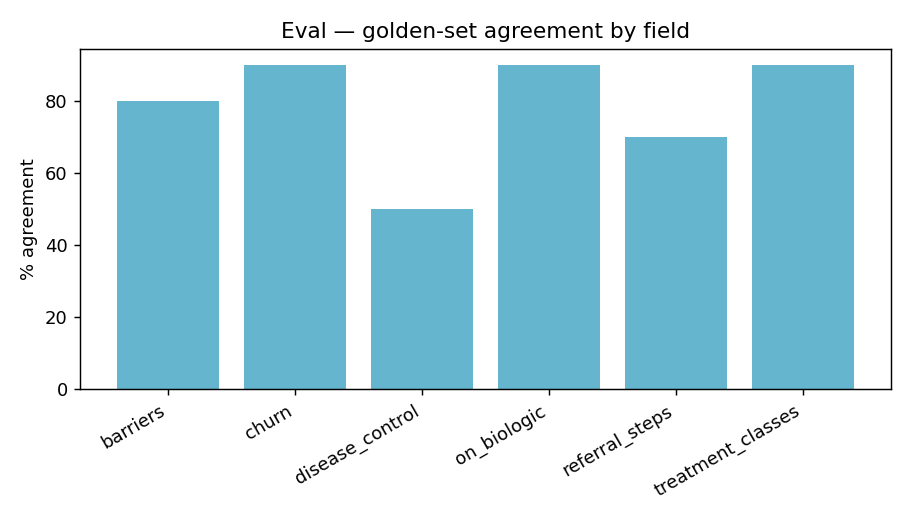

q1_biologic_status.png


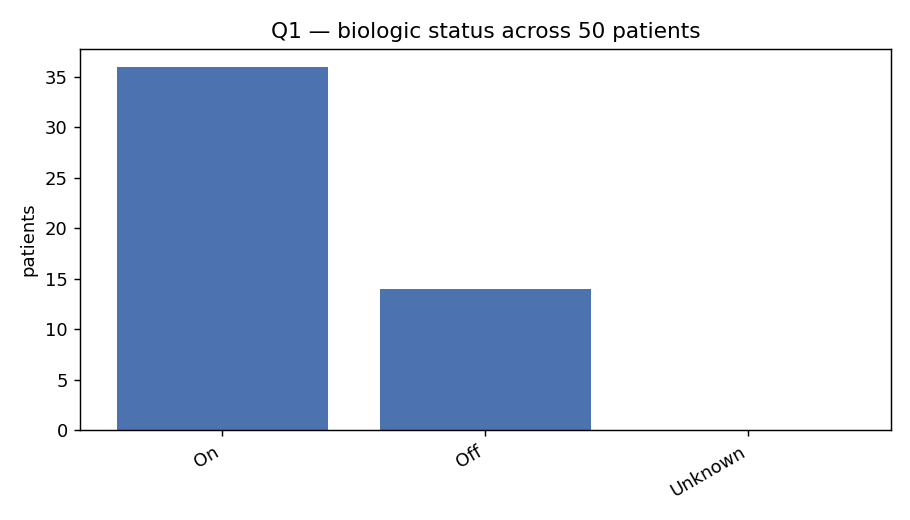

q2_barrier_frequency.png


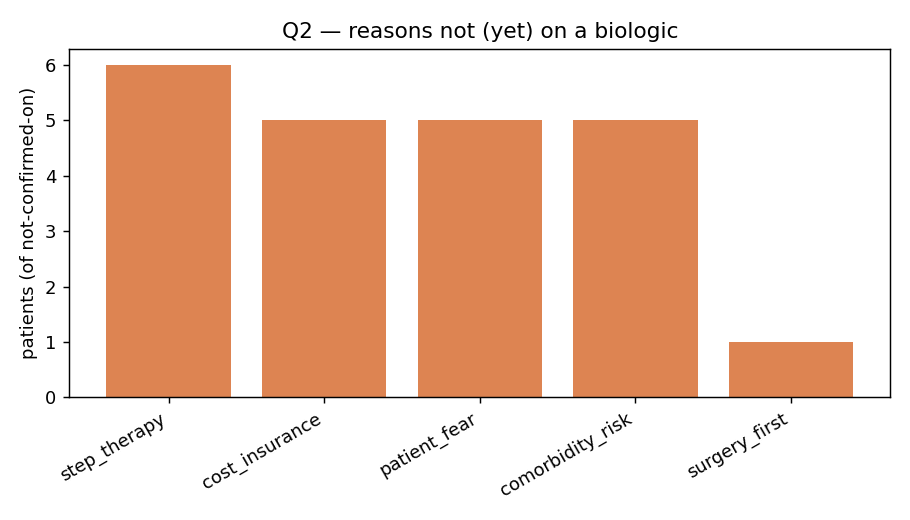

q3_treatment_class_frequency.png


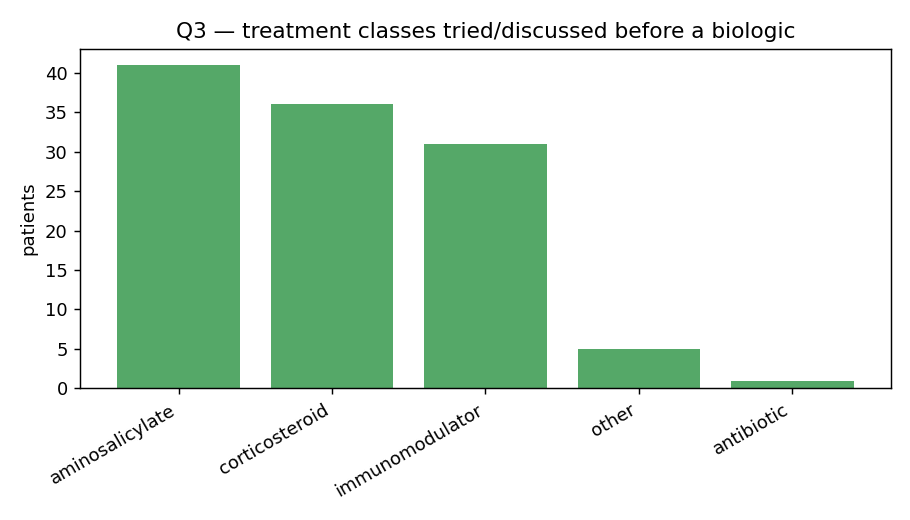

q4_entry_point_mix.png


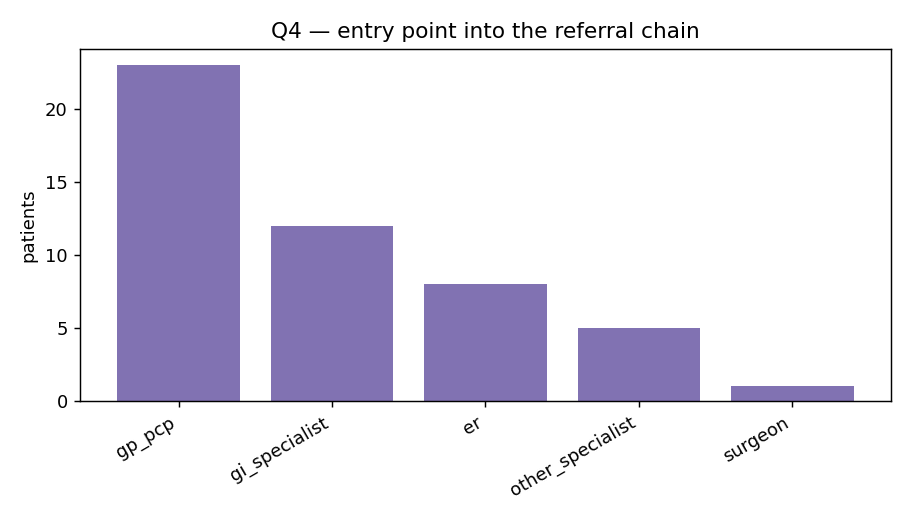

q4_step_histogram.png


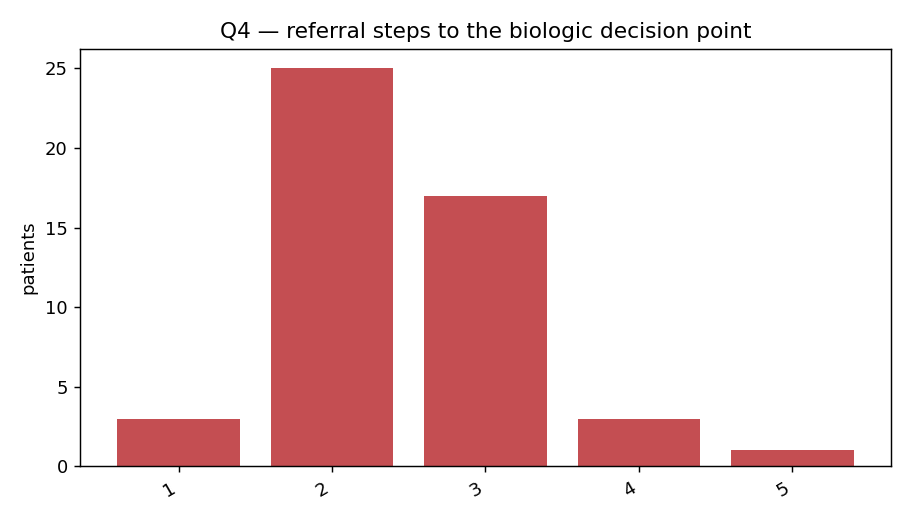

In [14]:
import analysis
analysis.main()

try:
    from IPython.display import Image, display
    for p in sorted(Path("data/outputs/charts").glob("*.png")):
        print(p.name)
        display(Image(filename=str(p)))
except ImportError:
    print("(not running in Jupyter/IPython — open the PNGs directly from data/outputs/charts/)")
